# Frame aggregation against score aggregation

`arcface_anonymizers_frame_aggregation` asks whether collapsing many anonymized frames into one
reconstruction — the `Facial` model from `06_facial` — recovers identity that the pipeline's
existing fusion does not.

Both legs now vary the frame aggregator, so the grid is **4 gallery anonymizations x 2 gallery
aggregators x 4 samples anonymizations x 2 samples aggregators x 3 score aggregators = 192 cells**,
1,892 identity-videos each.

That matters, because only one of the four aggregator pairings is the attack this project is
about: **`Facial` on the samples, an untouched gallery.** The gallery is what an attacker already
holds and the samples are what they observe, so a de-anonymization belongs on the samples leg.
Section 2 is that cell; everything else is context for it.

One structural fact to carry through the whole notebook: `video_facial` collapses an
identity-video to **a single frame**, where `video_none` leaves 48-75. That is the aggregation
working as designed, but it changes cardinality as well as content, and section 4 shows it has a
consequence that is easy to miss.

## Load

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

RESULTS_PATH = Path("../../results")
EXPERIMENT_NAME = "arcface_anonymizers_frame_aggregation"

ANONYMIZATION = {"none": "None", "gaussianblur": "Gaussian blur",
                 "blackbar": "Black bar", "pixelation": "Pixelation"}
AGGREGATION = {"video_none": "None (all frames)", "video_facial": "Facial (1 reconstruction)"}
# 'max' is the gallery side; the suffix is how a video's per-frame votes are pooled.
SCORE = {"max_none": "max_none (no pooling)", "max_mean": "max_mean", "max_max": "max_max"}
METRICS = ["top-1", "top-5", "top-10"]

sns.set_theme(style="whitegrid")

In [2]:
raw = pd.read_parquet(RESULTS_PATH / f"{EXPERIMENT_NAME}.parquet")
CHANCE = 1 / raw["identity"].nunique()

data = raw.replace({
    "samples_frame_anonymization": ANONYMIZATION,
    "gallery_frame_anonymization": ANONYMIZATION,
    "samples_frame_aggregation": AGGREGATION,
    "gallery_frame_aggregation": AGGREGATION,
    "score_aggregation": SCORE,
})
ANON_ORDER = [ANONYMIZATION[k] for k in ("none", "gaussianblur", "pixelation", "blackbar")]
SCORE_ORDER = [SCORE[k] for k in ("max_none", "max_mean", "max_max")]
AGG_ORDER = [AGGREGATION[k] for k in ("video_none", "video_facial")]
NONE, FACIAL = AGG_ORDER

cells = data.groupby(["gallery_frame_anonymization", "gallery_frame_aggregation",
                      "samples_frame_anonymization", "samples_frame_aggregation",
                      "score_aggregation"]).size()
print(f"{len(raw):,} rows over {len(cells)} grid cells, {cells.iloc[0]:,} identity-videos each")
print(f"identities {raw['identity'].nunique()}, chance {CHANCE:.4f}, folds {sorted(raw['fold'].unique())}")
data.head(3)

363,264 rows over 192 grid cells, 1,892 identity-videos each
identities 533, chance 0.0019, folds [np.int64(1), np.int64(2), np.int64(3)]


,identity,video,observations,top-1,top-5,top-10,predicted,fold,gallery_frame_anonymization,gallery_frame_aggregation,gallery_frame_embedding,gallery_embedding_aggregation,samples_frame_anonymization,samples_frame_aggregation,samples_frame_embedding,samples_embedding_aggregation,score_aggregation,pipeline
0,Aaron_Eckhart,2,56,0.946429,0.964286,0.982143,Aaron_Eckhart,1,None,None (all frames),arcface,video_none,None,None (all frames),arcface,video_none,max_none (no pooling),frame
1,Abdel_Aziz_Al-Hakim,0,75,1.000000,1.000000,1.000000,Abdel_Aziz_Al-Hakim,1,None,None (all frames),arcface,video_none,None,None (all frames),arcface,video_none,max_none (no pooling),frame
2,Abdullah_Gul,1,61,1.000000,1.000000,1.000000,Abdullah_Gul,1,None,None (all frames),arcface,video_none,None,None (all frames),arcface,video_none,max_none (no pooling),frame


## 1. The four aggregator pairings

Orientation before any detail. Each quadrant is one combination of what built the gallery and what
built the samples, averaged over every anonymization pair and score aggregator.

The top-left cell is the pipeline as it was. The bottom-left is the attack.

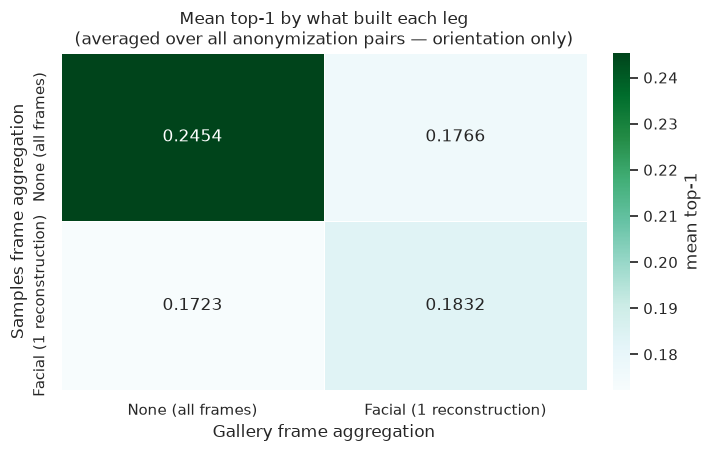

gallery_frame_aggregation  None (all frames)  Facial (1 reconstruction)
samples_frame_aggregation                                              
None (all frames)                     0.2454                     0.1766
Facial (1 reconstruction)             0.1723                     0.1832

Averaged over every anonymization pair, including ones where both legs are destroyed,
so read this as a map of the grid rather than as a result. Section 2 is the result.


In [3]:
pairing = (data.groupby(["samples_frame_aggregation", "gallery_frame_aggregation"])["top-1"]
           .mean().unstack().reindex(index=AGG_ORDER, columns=AGG_ORDER))

fig, ax = plt.subplots(figsize=(7, 4.4), layout="constrained")
sns.heatmap(pairing, annot=True, fmt=".4f", cmap="BuGn", linewidths=0.6, linecolor="w",
            cbar_kws={"label": "mean top-1"}, ax=ax)
ax.set_title("Mean top-1 by what built each leg\n(averaged over all anonymization pairs — orientation only)")
ax.set_xlabel("Gallery frame aggregation")
ax.set_ylabel("Samples frame aggregation")
plt.show()

print(pairing.to_string(float_format="%.4f"))
print("\nAveraged over every anonymization pair, including ones where both legs are destroyed,")
print("so read this as a map of the grid rather than as a result. Section 2 is the result.")

## 2. The attack: an untouched clear gallery against anonymized samples

The only pairing that asks the project's question. The attacker holds clear reference frames
(`gallery = None`, aggregator `None`, so all 48-75 frames survive) and observes anonymized ones,
either raw or reconstructed by `Facial`.

Both sides score the *same* 1,892 identity-videos, so the comparison is paired and the difference
can be tested directly rather than eyeballed from two error bars.

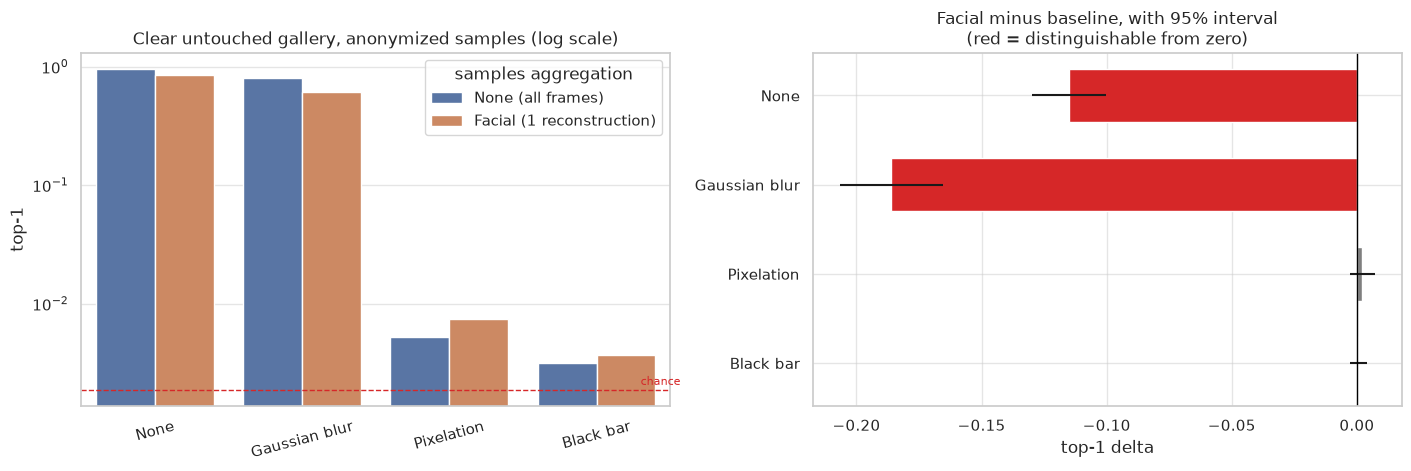

                none  facial   delta     se        t     n
anonymization                                             
None          0.9598  0.8446 -0.1152 0.0075 -15.3010  1892
Gaussian blur 0.7960  0.6099 -0.1860 0.0105 -17.6726  1892
Pixelation    0.0053  0.0074  0.0021 0.0026   0.8164  1892
Black bar     0.0032  0.0037  0.0005 0.0018   0.3014  1892

|t| >= 2 is distinguishable from zero at this sample size.


In [4]:
attack = data[(data["gallery_frame_anonymization"] == "None")
              & (data["gallery_frame_aggregation"] == NONE)
              & (data["score_aggregation"] == SCORE["max_mean"])]

key = ["identity", "video", "fold"]
rows = []
for anon in ANON_ORDER:
    sub = attack[attack["samples_frame_anonymization"] == anon]
    baseline = sub[sub["samples_frame_aggregation"] == NONE].set_index(key)["top-1"]
    facial = sub[sub["samples_frame_aggregation"] == FACIAL].set_index(key)["top-1"]
    joined = pd.concat([baseline.rename("none"), facial.rename("facial")], axis=1).dropna()
    difference = joined["facial"] - joined["none"]
    error = difference.std(ddof=1) / np.sqrt(len(difference))
    rows.append({"anonymization": anon, "none": joined["none"].mean(),
                 "facial": joined["facial"].mean(), "delta": difference.mean(),
                 "se": error, "t": difference.mean() / error, "n": len(joined)})
paired = pd.DataFrame(rows).set_index("anonymization")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), layout="constrained")
melted = paired[["none", "facial"]].rename(columns={"none": NONE, "facial": FACIAL}).reset_index().melt(
    id_vars="anonymization", var_name="samples aggregation", value_name="top-1")
sns.barplot(data=melted, x="anonymization", y="top-1", hue="samples aggregation",
            order=ANON_ORDER, hue_order=AGG_ORDER, ax=axes[0])
axes[0].set_yscale("log")
axes[0].axhline(CHANCE, color="tab:red", linestyle="--", linewidth=1)
axes[0].text(3.3, CHANCE * 1.1, "chance", color="tab:red", fontsize=8)
axes[0].set_title("Clear untouched gallery, anonymized samples (log scale)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=15)

# |t| >= 2 is the usual two-sided 5% threshold at this sample size.
colours = ["tab:red" if abs(t) >= 2 else "tab:grey" for t in paired["t"]]
axes[1].barh(range(len(paired)), paired["delta"], xerr=1.96 * paired["se"],
             color=colours, height=0.6)
axes[1].set_yticks(range(len(paired)), paired.index)
axes[1].axvline(0, color="black", linewidth=1)
axes[1].invert_yaxis()
axes[1].set_title("Facial minus baseline, with 95% interval\n(red = distinguishable from zero)")
axes[1].set_xlabel("top-1 delta")
plt.show()

print(paired.to_string(float_format="%.4f"))
print("\n|t| >= 2 is distinguishable from zero at this sample size.")

Read the right-hand panel before the left one.

**Where recognition works, the model destroys it.** Clear samples fall 0.96 to 0.84 and Gaussian
blur 0.80 to 0.61, both with |t| well above 15 — not close calls.

**Where anonymization works, the model changes nothing measurable.** Pixelation and black bar
move by +0.002 and +0.001, with |t| of 0.8 and 0.3. Those are the two cells the attack exists for,
and the honest reading is a null result, not a small win: at this sample size a real effect of that
size would not be detectable either way, so the experiment cannot distinguish "no help" from "a
little help".

It is worth being explicit about what *looks* like a win. Pixelation goes from 2.8x chance to 3.9x
chance, a 40% relative lift, and quoting it that way would be indefensible — the absolute change
is 0.002 and the paired test puts it inside the noise.

## 3. Score aggregation, the fusion that already worked

`score_aggregation` pools a video's per-frame votes before deciding. `max_none` does not pool, so
it is the genuine one-observation floor; `max_mean` and `max_max` fuse across a video's frames.

This is what `Facial` has to beat: the same idea — combine many observations of one video — applied
after the recogniser instead of before it, with no model and no training.

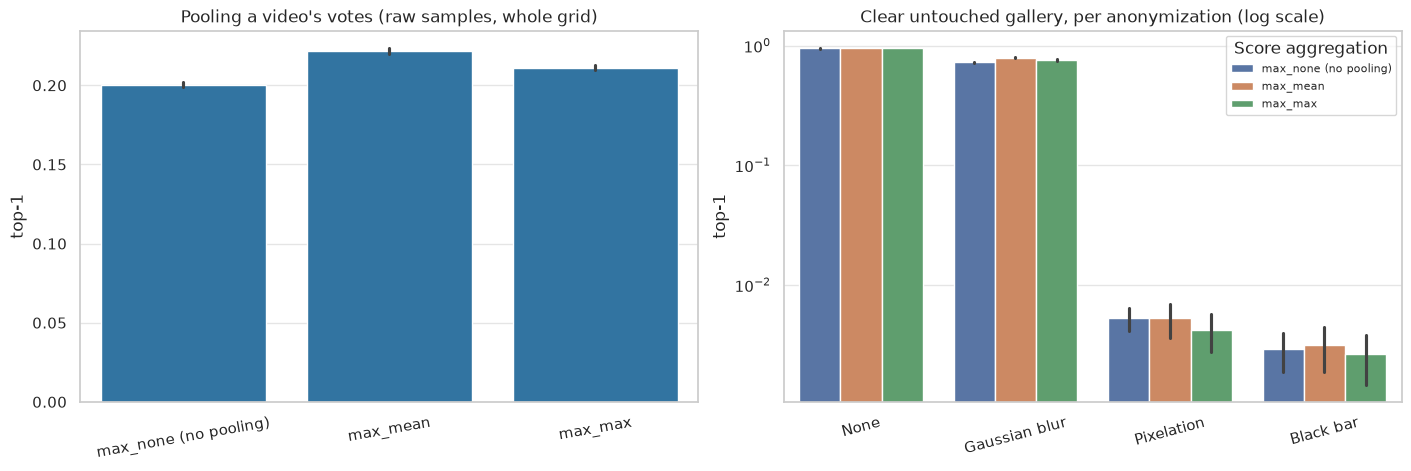

score_aggregation
max_none (no pooling)   0.2004
max_mean                0.2217
max_max                 0.2110

best pooling beats the no-pooling floor by +0.0213 top-1


In [5]:
baseline = data[data["samples_frame_aggregation"] == NONE]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), layout="constrained")
sns.barplot(data=baseline, x="score_aggregation", y="top-1", order=SCORE_ORDER,
            errorbar="se", color="tab:blue", ax=axes[0])
axes[0].set_title("Pooling a video's votes (raw samples, whole grid)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=10)

clear = baseline[(baseline["gallery_frame_anonymization"] == "None")
                 & (baseline["gallery_frame_aggregation"] == NONE)]
sns.barplot(data=clear, x="samples_frame_anonymization", y="top-1", hue="score_aggregation",
            order=ANON_ORDER, hue_order=SCORE_ORDER, errorbar="se", ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_title("Clear untouched gallery, per anonymization (log scale)")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=15)
axes[1].legend(title="Score aggregation", fontsize=8)
plt.show()

pooled = baseline.groupby("score_aggregation")["top-1"].mean().reindex(SCORE_ORDER)
print(pooled.to_string(float_format="%.4f"))
print(f"\nbest pooling beats the no-pooling floor by {pooled.max() - pooled.iloc[0]:+.4f} top-1")

## 4. The two cannot be combined

`Facial` leaves one frame per identity-video. `score_aggregation` pools *across a video's frames*.
With one frame there is nothing to pool, so choosing the model does not add a fusion stage — it
**removes** the one that already worked.

The check below is the whole argument: with raw samples the three score aggregators differ; with
reconstructed samples they are bit-for-bit identical.

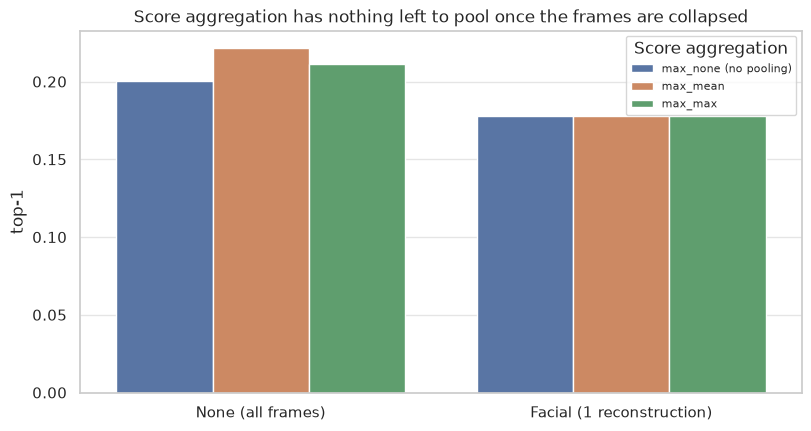

score_aggregation          max_none (no pooling)  max_mean  max_max  spread
samples_frame_aggregation                                                  
None (all frames)                        0.20037   0.22166  0.21104 0.02128
Facial (1 reconstruction)                0.17772   0.17772  0.17772 0.00000

                            total  per identity-video
aggregation                                          
None (all frames)          130727                69.1
Facial (1 reconstruction)    1892                 1.0


In [6]:
spread = (data.groupby(["samples_frame_aggregation", "score_aggregation"])["top-1"]
          .mean().unstack().reindex(index=AGG_ORDER, columns=SCORE_ORDER))
spread["spread"] = spread.max(axis=1) - spread.min(axis=1)

frames = []
for key, label in AGGREGATION.items():
    path = RESULTS_PATH / "aggregate_frame" / "pixelation" / key / "structure.parquet"
    if path.exists():
        structure = pd.read_parquet(path, columns=["identity", "video"])
        per_video = structure.groupby(["identity", "video"]).size()
        frames.append({"aggregation": label, "total": len(structure),
                       "per identity-video": per_video.mean()})
frames = pd.DataFrame(frames).set_index("aggregation")

fig, ax = plt.subplots(figsize=(8, 4.2), layout="constrained")
melted = spread[SCORE_ORDER].reset_index().melt(id_vars="samples_frame_aggregation",
                                                var_name="score", value_name="top-1")
sns.barplot(data=melted, x="samples_frame_aggregation", y="top-1", hue="score",
            order=AGG_ORDER, hue_order=SCORE_ORDER, ax=ax)
ax.set_title("Score aggregation has nothing left to pool once the frames are collapsed")
ax.set_xlabel("")
ax.legend(title="Score aggregation", fontsize=8)
plt.show()

print(spread.to_string(float_format="%.5f"))
print()
print(frames.to_string(float_format="%.1f"))

## 5. Every pairing, as deltas

Section 2 took one slice. This is the same comparison everywhere: what each leg's aggregator is
worth, across both anonymizations and all three score aggregators.

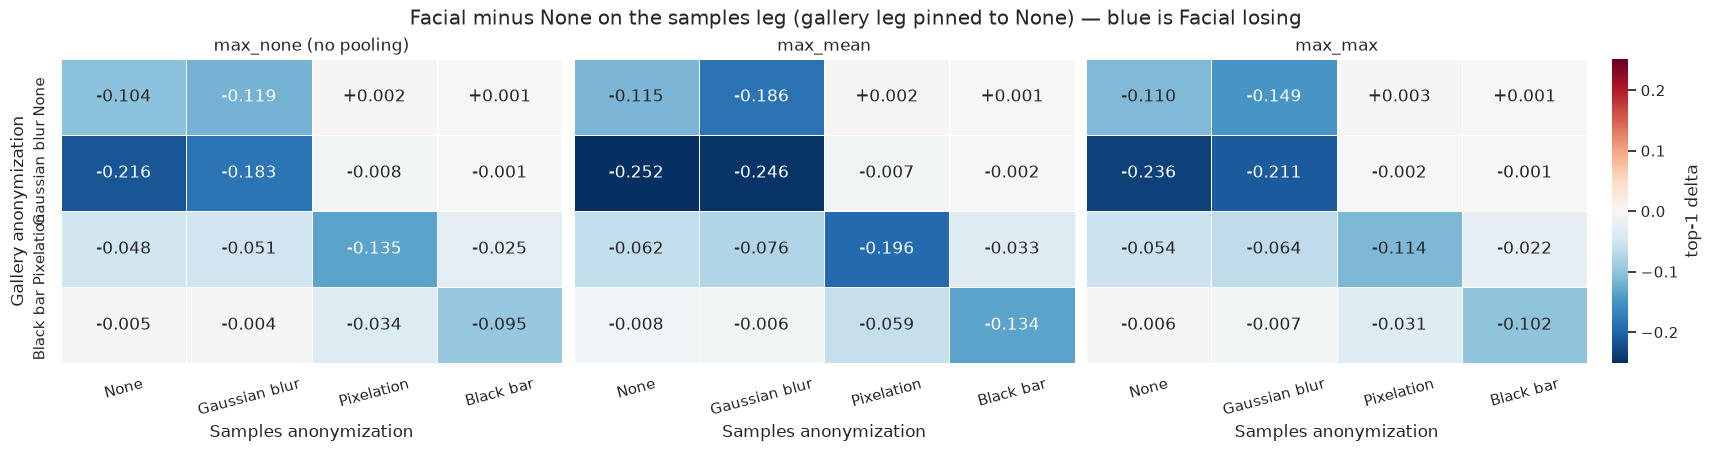

samples: Facial wins 6 of 48 cells, best +0.003, worst -0.252, mean -0.073


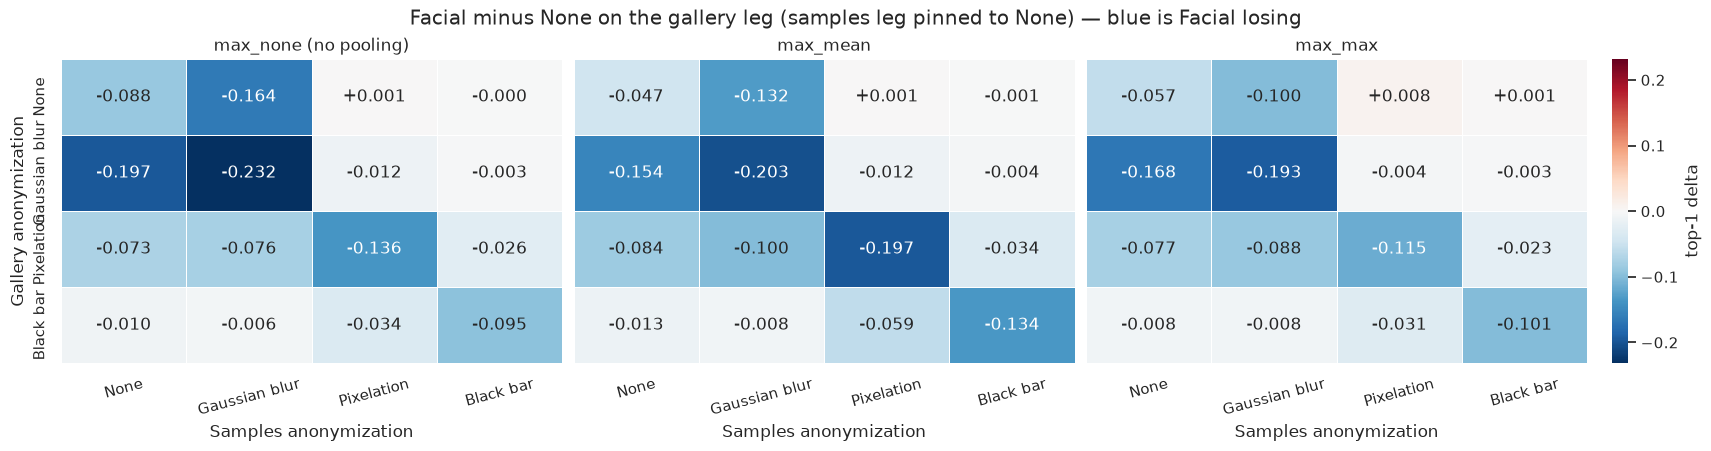

gallery: Facial wins 4 of 48 cells, best +0.008, worst -0.232, mean -0.069


In [7]:
for leg, other in (("samples", "gallery"), ("gallery", "samples")):
    held = NONE  # the other leg is pinned to the baseline, so one variable moves at a time
    subset = data[data[f"{other}_frame_aggregation"] == held]
    pivot = (subset.groupby(["score_aggregation", "gallery_frame_anonymization",
                             "samples_frame_anonymization", f"{leg}_frame_aggregation"])["top-1"]
             .mean().unstack())
    pivot["delta"] = pivot[FACIAL] - pivot[NONE]
    delta = pivot.reset_index()

    limit = delta["delta"].abs().max()
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.4), sharey=True, layout="constrained")
    for ax, score in zip(axes, SCORE_ORDER):
        frame = (delta[delta["score_aggregation"] == score]
                 .pivot(index="gallery_frame_anonymization", columns="samples_frame_anonymization",
                        values="delta").reindex(index=ANON_ORDER, columns=ANON_ORDER))
        sns.heatmap(frame, ax=ax, annot=True, fmt="+.3f", cmap="RdBu_r", center=0,
                    vmin=-limit, vmax=limit, linewidths=0.5, linecolor="w",
                    cbar=score == SCORE_ORDER[-1], cbar_kws={"label": "top-1 delta"})
        ax.set_title(score)
        ax.set_xlabel("Samples anonymization")
        ax.set_ylabel("Gallery anonymization" if score == SCORE_ORDER[0] else "")
        ax.tick_params(axis="x", rotation=15)
    fig.suptitle(f"Facial minus None on the {leg} leg ({other} leg pinned to None) — blue is Facial losing")
    plt.show()

    print(f"{leg}: Facial wins {(delta['delta'] > 0).sum()} of {len(delta)} cells, "
          f"best {delta['delta'].max():+.3f}, worst {delta['delta'].min():+.3f}, "
          f"mean {delta['delta'].mean():+.3f}")

## 6. The whole grid

All 192 cells. The sections above pull single slices out of this.

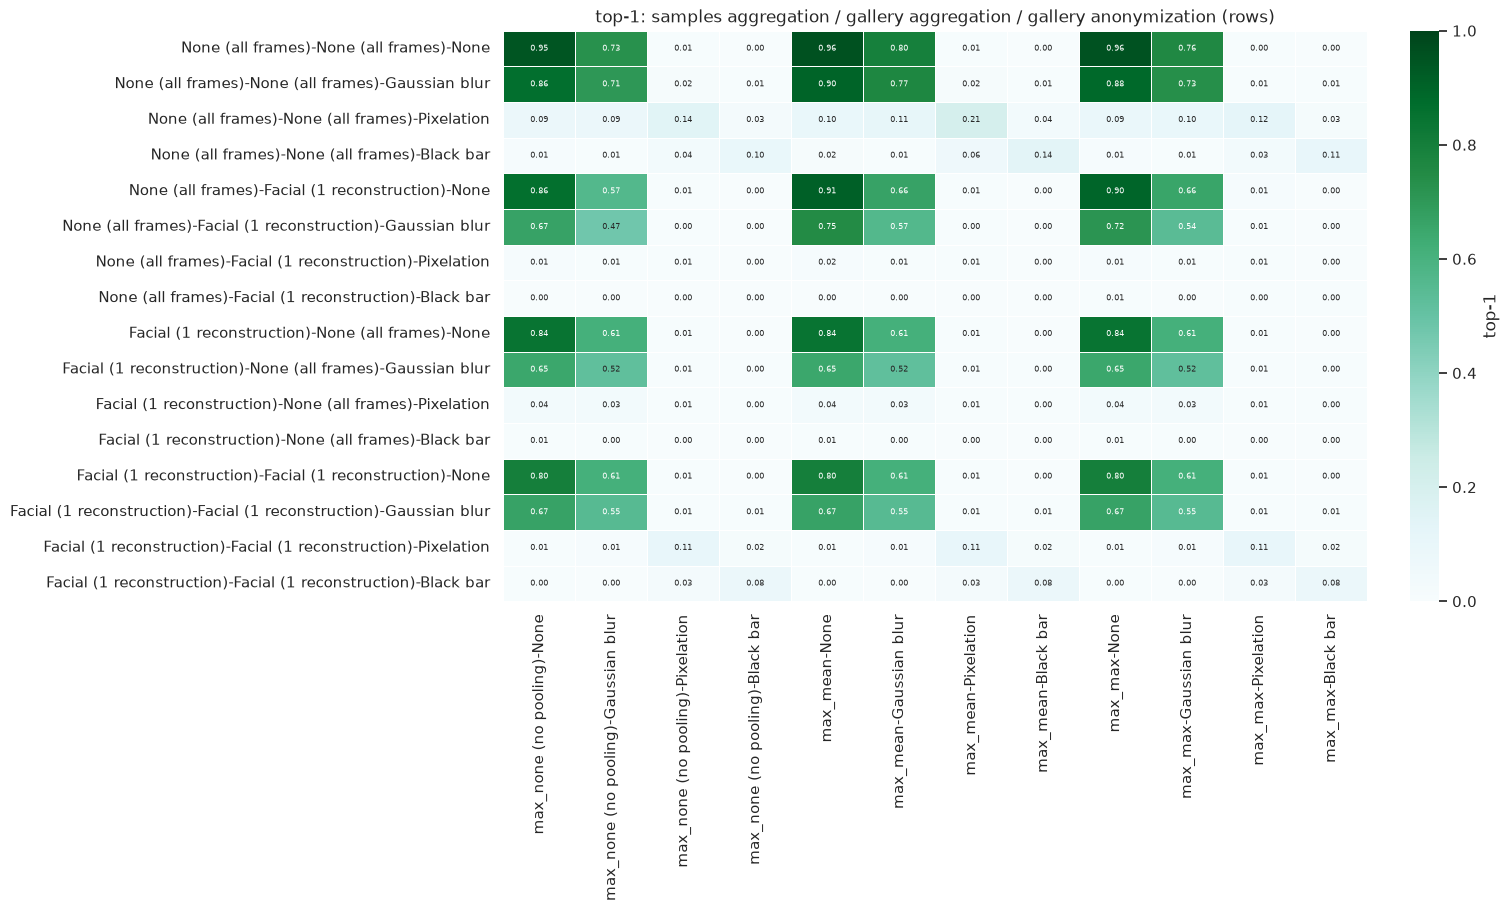

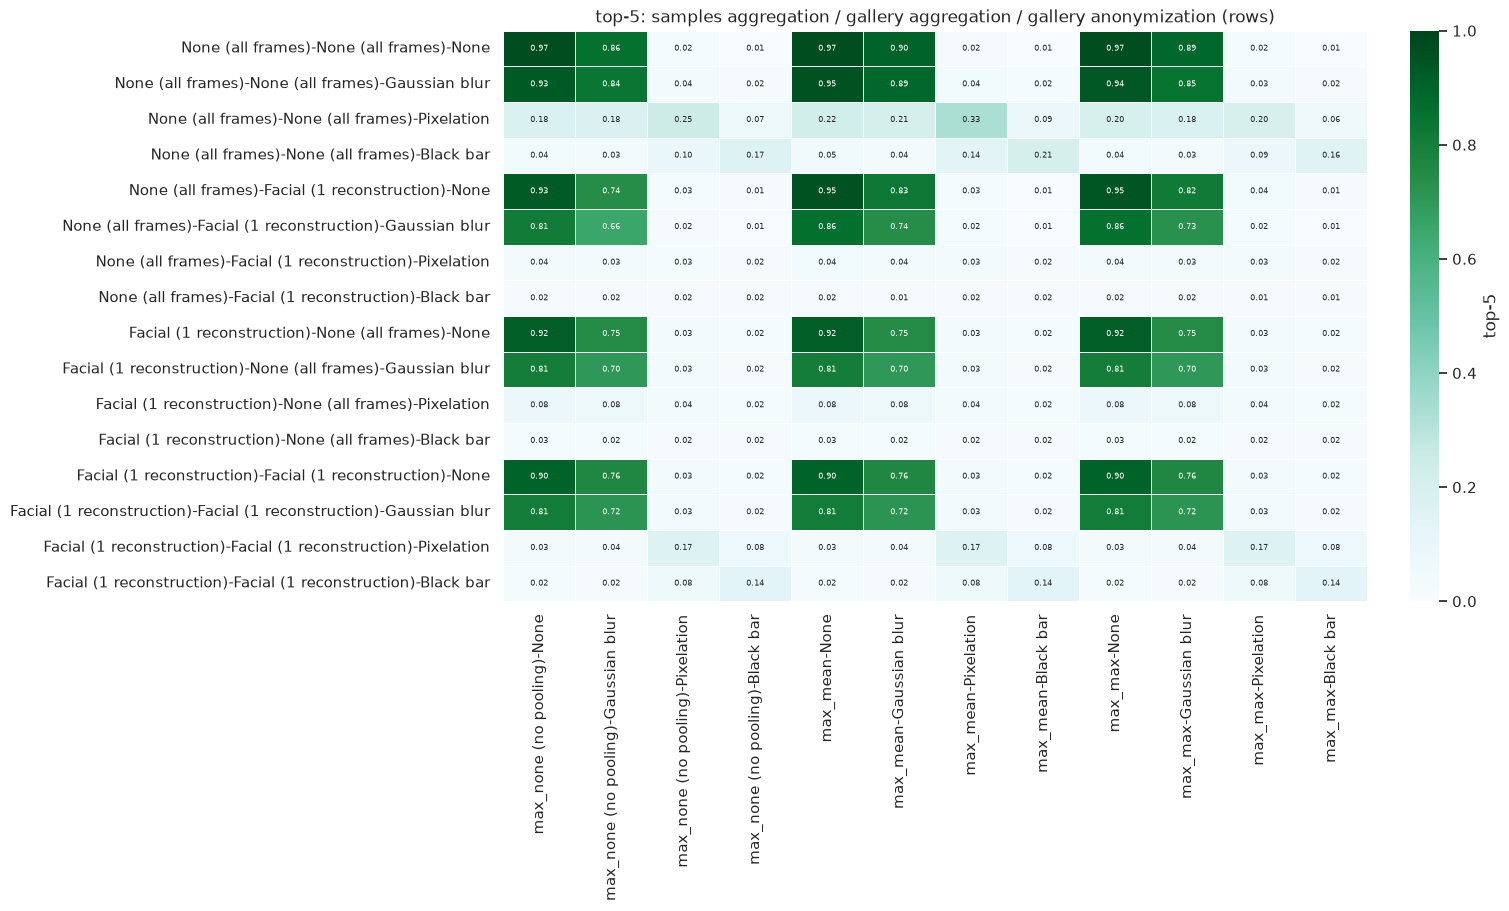

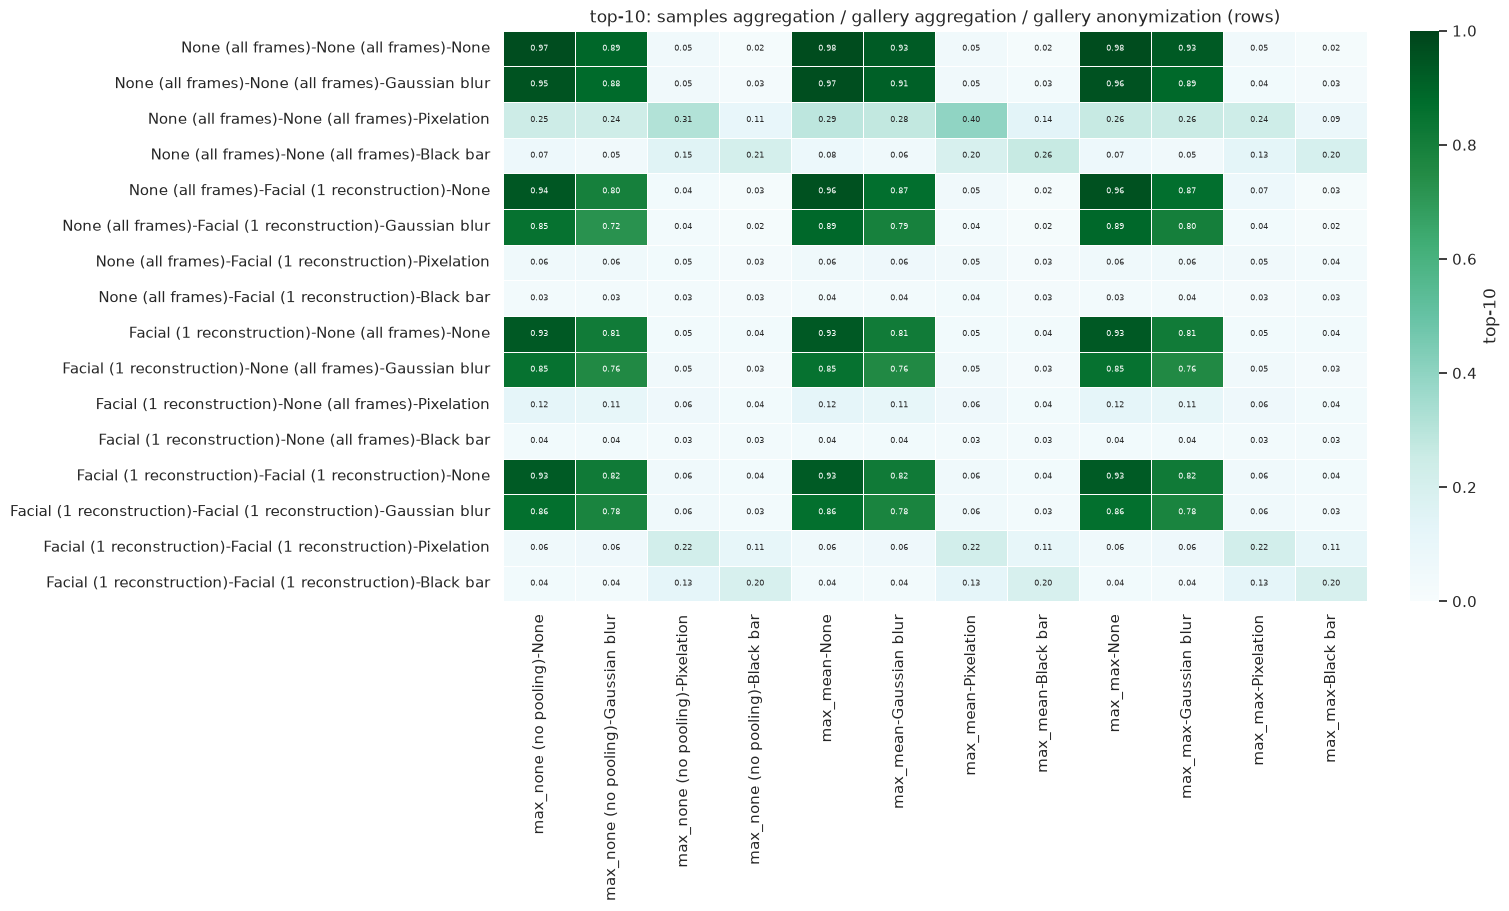

In [8]:
for metric in METRICS:
    frame = (data.pivot_table(index=["samples_frame_aggregation", "gallery_frame_aggregation",
                                     "gallery_frame_anonymization"],
                              columns=["score_aggregation", "samples_frame_anonymization"],
                              values=metric, aggfunc="mean")
             .reindex(index=pd.MultiIndex.from_product([AGG_ORDER, AGG_ORDER, ANON_ORDER]),
                      columns=pd.MultiIndex.from_product([SCORE_ORDER, ANON_ORDER])))
    fig, ax = plt.subplots(figsize=(15, 9), layout="constrained")
    sns.heatmap(frame, ax=ax, annot=True, fmt=".2f", annot_kws={"fontsize": 6},
                cmap="BuGn", vmin=0, vmax=1, linewidths=0.4, linecolor="w",
                cbar_kws={"label": metric})
    ax.set_title(f"{metric}: samples aggregation / gallery aggregation / gallery anonymization (rows)")
    ax.set_xlabel("")
    ax.set_ylabel("")
    plt.show()

## 7. Does seeing more of a video help?

Each row carries `observations`, the frames that identity-video contributed. If aggregation is
what recovers identity, accuracy should rise with it.

**This dataset can barely answer that.** `observations` runs 48 to 75 — a 1.6x range — and 63% of
rows sit at exactly 75, the per-video cap. Treat it as a weak consistency check. The real version
is the N=1..16 curve in `06_facial`, built by varying the input deliberately.

observations 48 to 75, 63% of rows at the cap


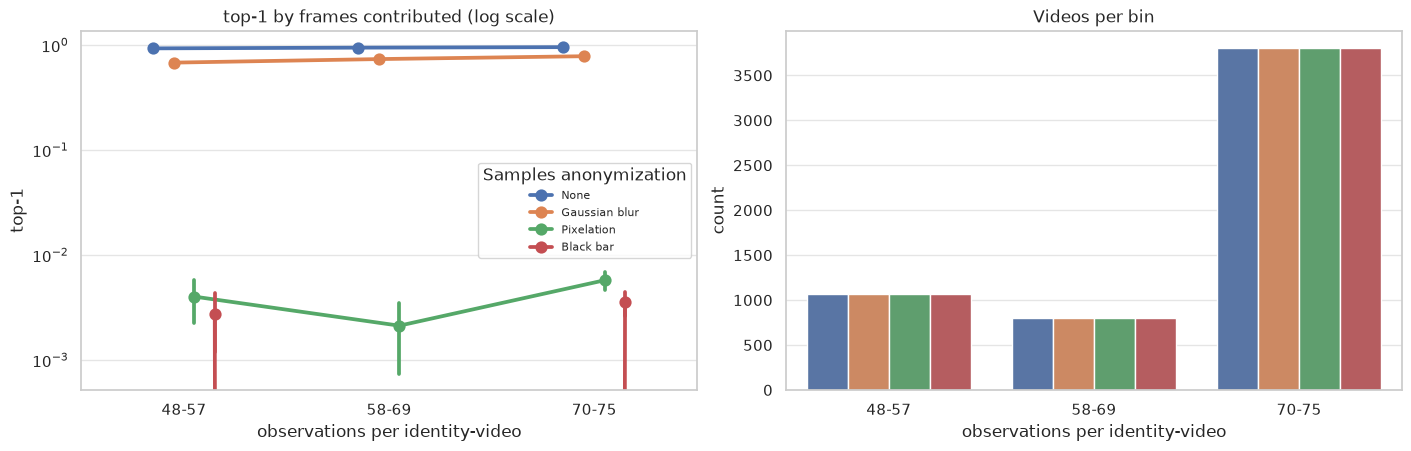


Spearman(observations, top-1):
  None           rho +0.055
  Gaussian blur  rho +0.091
  Pixelation     rho +0.034
  Black bar      rho +0.024


In [9]:
observed = data[(data["gallery_frame_anonymization"] == "None")
                & (data["gallery_frame_aggregation"] == NONE)
                & (data["samples_frame_aggregation"] == NONE)].copy()
observed["observations"] = observed["observations"].astype(int)
counts = observed["observations"].value_counts().sort_index()
print(f"observations {counts.index.min()} to {counts.index.max()}, "
      f"{counts.loc[75] / len(observed):.0%} of rows at the cap")

# Fixed bins, not quantiles: 63% of the mass is one value, so qcut collapses to two uneven buckets.
observed["bucket"] = pd.cut(observed["observations"], [47, 57, 69, 75],
                            labels=["48-57", "58-69", "70-75"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), layout="constrained")
sns.pointplot(data=observed, x="bucket", y="top-1", hue="samples_frame_anonymization",
              hue_order=ANON_ORDER, errorbar="se", dodge=0.3, ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_title("top-1 by frames contributed (log scale)")
axes[0].set_xlabel("observations per identity-video")
axes[0].legend(title="Samples anonymization", fontsize=8)
sns.countplot(data=observed, x="bucket", hue="samples_frame_anonymization",
              hue_order=ANON_ORDER, ax=axes[1])
axes[1].set_title("Videos per bin")
axes[1].set_xlabel("observations per identity-video")
axes[1].get_legend().remove()
plt.show()

print("\nSpearman(observations, top-1):")
for name in ANON_ORDER:
    rows = observed[observed["samples_frame_anonymization"] == name]
    print(f"  {name:<14} rho {rows['observations'].corr(rows['top-1'], method='spearman'):+.3f}")

## What this shows

**Score aggregation works and is free.** Pooling a video's votes beats not pooling across the
grid, with no model and no training.

**`Facial` on the samples leg does not beat it.** Where recognition works it is a large, certain
loss (clear -0.115, blur -0.186, both |t| > 15). Where anonymization works — the two cells the
attack exists for — it is a null result: +0.002 and +0.001 with |t| of 0.8 and 0.3.

**And it costs the fusion that did work.** One reconstruction per video leaves `score_aggregation`
nothing to pool; its spread falls from 0.021 to exactly 0.000. The two mechanisms are alternatives
on the samples leg, not a stack.

### Why this does not contradict `06_facial`

That notebook measured 78% top-1 on pixelation and 19% on black bar, verified against artifact and
colour shortcuts. Three differences, all unfavourable here, and none of them a defect in either
result:

1. **Scope.** A `video` group is one YouTube Faces video — ~3 seconds of near-duplicate frames at
   0.78 mean cosine. `Facial` trained on items spanning ~14 different videos. Measured directly in
   `06_facial`: 87.0% with 16 frames across videos against 29.0% with one. `aggregate_frame`
   refuses the `identity` scope, so the frame stage structurally cannot supply more.
2. **Gallery.** `06_facial` scored reconstructions against VoxCeleb2 targets the model was trained
   to produce. Here they are matched against YouTube Faces frames, a different corpus with
   different framing and colour.
3. **Alignment.** Training aligned crops using detection on the *clear* frame. In the sweep only
   the anonymized frame exists, so black bars and heavy pixelation can defeat detection before the
   model sees anything.

The first is the one worth acting on, and it is a property of the pipeline rather than of the
model: the thing that made `Facial` work is the thing `aggregate_frame`'s video scope cannot give
it.